# Minimum-Jerk Trajectories

Generate a smooth rest-to-rest motion with specified endpoint position, velocity and acceleration.

Minimising integrated squared jerk for a point with zero endpoint velocity and acceleration gives a fifth-order polynomial. For normalised time u, the progress law is 10u³ − 15u⁴ + 6u⁵. Differentiating with respect to physical time introduces one factor of inverse duration per derivative.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

## Check the boundary conditions

Compare the polynomial trajectory with linear progress, then inspect velocity, acceleration and jerk under two movement durations.

Duration 1.0 s | peak speed 2.344 m/s | integrated squared jerk 1125.045
Duration 1.6 s | peak speed 1.465 m/s | integrated squared jerk 107.293


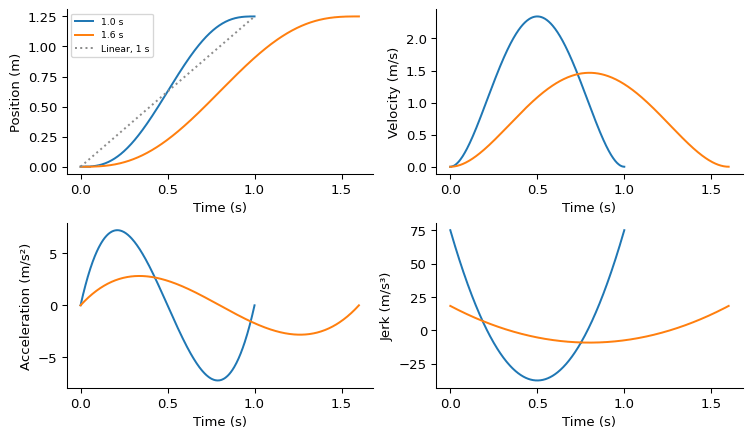

In [2]:
delta = 1.25
fig, axes = plt.subplots(2, 2, figsize=(7.8, 4.5), constrained_layout=True)
for T in [1.0, 1.6]:
    t = np.linspace(0, T, 501)
    u = t / T
    pos = delta * (10 * u**3 - 15 * u**4 + 6 * u**5)
    vel = delta / T * (30 * u**2 - 60 * u**3 + 30 * u**4)
    acc = delta / T**2 * (60 * u - 180 * u**2 + 120 * u**3)
    jerk = delta / T**3 * (60 - 360 * u + 360 * u * u)
    assert np.allclose([pos[0], pos[-1], *vel[[0, -1]], *acc[[0, -1]]], [0, delta, 0, 0, 0, 0])
    energy = np.trapezoid(jerk**2, t)
    analytic = 720 * delta**2 / T**5
    assert np.isclose(energy, analytic, rtol=0.0001)
    print(
        f"Duration {T:.1f} s | peak speed {vel.max():.3f} m/s | integrated squared jerk {energy:.3f}"
    )
    for ax, signal, label in zip(
        axes.ravel(),
        [pos, vel, acc, jerk],
        ["Position (m)", "Velocity (m/s)", "Acceleration (m/s²)", "Jerk (m/s³)"],
    ):
        ax.plot(t, signal, label=f"{T:.1f} s")
        ax.set(xlabel="Time (s)", ylabel=label)
axes[0, 0].plot([0, 1], [0, delta], ":", color="0.55", label="Linear, 1 s")
axes[0, 0].legend(fontsize=7)
plt.show()

## Interpreting the result

Stretching the same path in time reduces integrated squared jerk in proportion to T⁻⁵. A physical arm would also require joint and actuator checks.

## Exercise

Double the duration and verify the predicted ratio of the two jerk energies.

## References

[Flash and Hogan, coordination of arm movements (1985)](https://doi.org/10.1523/JNEUROSCI.05-07-01688.1985)